# 🧬 Layer 19: PocketVina Multi-Pocket SAS Conditioning & 21-Check PoseBusters Gate in SQL

Inspired by **PocketVina Atlas** ([Sarigun et al., *arXiv:2506.20043*](https://arxiv.org/abs/2506.20043); [pocketvina-atlas.mdc-berlin.de](https://pocketvina-atlas.mdc-berlin.de/about/)) and **PoseBusters** ([Buttenschoen et al., *Chem. Sci.* 2024](https://doi.org/10.1039/D3SC04185A)), this notebook demonstrates `pg_bio`'s native Rust execution of:
1. **`bio_detect_top_pockets(pdb, 5)`**: P2Rank-inspired 24-ray Fibonacci Connolly Solvent Accessible Surface (SAS) concavity detection + $5.0\,\text{\AA}$ 3D voxel hashing + 9D `RangeFinderPocket` & 16-byte register Fastscan (`bytea`) emission across the top 5 pockets (`pk1..pk5`).
2. **`bio_posebusters_audit` & `bio_posebusters_audit_row`**: Sub-2-millisecond 21-check physical, chemical, salt-hygiene, $3\times 3$ Jacobi SVD aromatic ring flatness, and pairwise van der Waals steric clash validation ($d / (r_{\text{vdW},i}+r_{\text{vdW},j}) \ge 0.75$).
3. **`bio_multipocket_posebusters_screen`**: End-to-end multi-pocket conditioning across our industrial bioprocess feedstocks (e.g., **Diclofenac**, **Ferulic Acid**, **Terephthalic Acid**) and salted vendor drug entries (`[Na+].O=C([O-])c1ccccc1O`).

In [1]:
import os
import time
import psycopg
import pandas as pd
import matplotlib.pyplot as plt

DB_URI = os.getenv("PG_BIO_URL", "postgresql://localhost:28818/bio_demo")
conn = psycopg.connect(DB_URI, autocommit=True)
cur = conn.cursor()
print("Connected to PostgreSQL 18 + pg_bio!")

Connected to PostgreSQL 18 + pg_bio!


In [2]:
# Build a multi-pocket enzyme structure with 3 distinct concave binding clefts:
#   - pk1 (Primary Catalytic Cleft around (10, 10, 10): rich in TRP/HIS/TYR/ASP/GLU)
#   - pk2 (Allosteric Seam around (32, 10, 10): rich in PHE/LEU/GLU/VAL)
#   - pk3 (Cryptic Surface Pocket around (10, 32, 10): rich in CYS/MET/SER/ILE)
from scripts.benchmark_pocketvina_posebusters import build_multipocket_protein_pdb

enzyme_pdb = build_multipocket_protein_pdb(0)
cur.execute(
    """
    SELECT pocket_rank, pocket_id, p2rank_score, probability,
           center_x, center_y, center_z, sas_points_count, residue_count,
           mean_plddt, residue_ids[1:4] AS sample_residues,
           round((pocket_ranges::text::json->>'mw_min')::numeric, 1) AS mw_min,
           round((pocket_ranges::text::json->>'mw_max')::numeric, 1) AS mw_max,
           octet_length(fastscan_16b) AS fastscan_bytes
    FROM bio_detect_top_pockets(%s, 5);
    """,
    (enzyme_pdb,),
)
cols = [d.name for d in cur.description]
df_pockets = pd.DataFrame(cur.fetchall(), columns=cols)
df_pockets

,pocket_rank,pocket_id,p2rank_score,probability,center_x,center_y,center_z,sas_points_count,residue_count,mean_plddt,sample_residues,mw_min,mw_max,fastscan_bytes
0,1,pk1,415.78,0.995,10.239,10.104,9.995,123,10,93.8,"[A:TRP10, A:HIS11, A:TYR12, A:ASP13]",102.5,278.9,16
1,2,pk2,165.73,0.995,30.261,8.928,9.940,61,7,93.8,"[A:PHE40, A:LEU41, A:GLU42, A:VAL43]",98.0,274.2,16
2,3,pk3,91.46,0.995,10.349,31.217,9.692,36,5,93.8,"[A:CYS70, A:MET71, A:SER72, A:ILE73]",92.5,266.9,16


In [3]:
# Audit 7 chemical archetypes across all 21 PoseBusters checks directly inside SQL:
# Includes PocketVina Atlas's salt edge cases (Salted drug rescued vs. Bare counterion rejected) + clashing 3D HETATM pose
clashing_hetatm = "\n".join([
    "HETATM    1  C1  LIG L   1       6.250  10.000  10.000  1.00  0.00           C",
    "HETATM    2  C2  LIG L   1       7.650  10.000  10.000  1.00  0.00           C",
    "HETATM    3  O1  LIG L   1       8.850  10.000  10.000  1.00  0.00           O",
])

test_cases = [
    ("1. Sodium Salicylate Salt (Auto-Desalted Drug)", "[Na+].O=C([O-])c1ccccc1O"),
    ("2. Diclofenac (Pipeline #6 Biochar Feedstock)", "O=C(O)Cc1ccccc1Nc2c(Cl)cccc2Cl"),
    ("3. Ferulic Acid (Pipeline #4 Corn Stover Feedstock)", "COc1cc(/C=C/C(=O)O)ccc1O"),
    ("4. Terephthalic Acid (Pipeline #2 PET Upcycling)", "OC(=O)c1ccc(C(=O)O)cc1"),
    ("5. Aspirin (Approved Drug Benchmark)", "CC(=O)Oc1ccccc1C(=O)O"),
    ("6. p-Benzoquinone (PAINS Redox Cycler Trap)", "O=C1C=CC(=O)C=C1"),
    ("7. Bare Salt Counterion [Na+] (PocketVina Salt Trap)", "[Na+]"),
    ("8. Sterically Clashing 3D HETATM Pose (d=0.05 Å)", clashing_hetatm),
]

audit_rows = []
for label, lig in test_cases:
    cur.execute(
        """
        SELECT passes_all_21, raw_passes_all_21, was_desalted, rescue_possible,
               rescue_rmsd_shift_a, provenance_tag, passed_count, total_checks,
               failed_checks, protein_steric_clash_ok, salt_stripped_drug,
               pains_aggregator_clean, min_vdw_ratio, max_ring_rmsd_a, ligand_heavy_atoms
        FROM bio_posebusters_audit_row(%s, %s, 10.0, 10.0, 10.0);
        """,
        (enzyme_pdb, lig),
    )
    r = cur.fetchone()
    audit_rows.append({
        "Archetype": label,
        "PoseBusters Gate": "✅ 21/21 VALID" if r[0] else f"❌ {r[6]}/{r[7]} FAILED",
        "Raw As-Screened": r[1],
        "Was Desalted": r[2],
        "Rescuable (<=1.25Å)": f"{r[3]} ({r[4]} Å)",
        "Provenance Tag": r[5],
        "Failed Checks": ", ".join(r[8]) if r[8] else "—",
        "Min VdW Ratio (>=0.75)": r[12],
        "Ring Planar RMSD (Å)": r[13],
        "Heavy Atoms": r[14],
    })

df_audit = pd.DataFrame(audit_rows)
df_audit

,Archetype,PoseBusters Gate,Raw As-Screened,Was Desalted,Rescuable (<=1.25Å),Provenance Tag,Failed Checks,Min VdW Ratio (>=0.75),Ring Planar RMSD (Å),Heavy Atoms
0,1. Sodium Salicylate Salt (Auto-Desalted Drug),✅ 21/21 VALID,False,True,True (0.0 Å),desalted_from_salt,—,1.151,0.0,10
1,2. Diclofenac (Pipeline #6 Biochar Feedstock),✅ 21/21 VALID,True,False,True (0.0 Å),as_screened_valid,—,1.136,0.0,19
2,3. Ferulic Acid (Pipeline #4 Corn Stover Feeds...,✅ 21/21 VALID,True,False,True (0.0 Å),as_screened_valid,—,1.160,0.0,14
3,4. Terephthalic Acid (Pipeline #2 PET Upcycling),✅ 21/21 VALID,True,False,True (0.0 Å),as_screened_valid,—,1.160,0.0,12
4,5. Aspirin (Approved Drug Benchmark),✅ 21/21 VALID,True,False,True (0.0 Å),as_screened_valid,—,0.784,0.0,13
5,6. p-Benzoquinone (PAINS Redox Cycler Trap),❌ 20/21 FAILED,False,False,False (0.0 Å),pains_or_aggregator_alert,pains_aggregator_clean,1.162,0.0,8
6,7. Bare Salt Counterion [Na+] (PocketVina Salt...,❌ 19/21 FAILED,False,False,False (0.0 Å),non_drug_counterion,"salt_stripped_drug, rangefinder_8prop_compatible",0.842,0.0,1
7,8. Sterically Clashing 3D HETATM Pose (d=0.05 Å),❌ 16/21 FAILED,False,False,False (0.0 Å),steric_exclusion_rejected,"bond_angles_ok, internal_energy_strain_ok, pro...",0.015,0.0,3


In [4]:
# Execute Multi-Pocket Conditioning (`bio_multipocket_posebusters_screen`) for Diclofenac across all detected pockets:
cur.execute(
    """
    SELECT pocket_rank,
           CASE WHEN is_best_pocket THEN '★ ' || pocket_id ELSE pocket_id END AS pocket_badge,
           p2rank_score, pocket_probability, estimated_vina_kcal_mol,
           rangefinder_compatibility, posebusters_valid, posebusters_passed_checks,
           min_vdw_ratio, contact_residues[1:4] AS top_contacts
    FROM bio_multipocket_posebusters_screen(%s, %s, 5);
    """,
    (enzyme_pdb, "O=C(O)Cc1ccccc1Nc2c(Cl)cccc2Cl"),
)
df_screen = pd.DataFrame(cur.fetchall(), columns=[d.name for d in cur.description])
df_screen

,pocket_rank,pocket_badge,p2rank_score,pocket_probability,estimated_vina_kcal_mol,rangefinder_compatibility,posebusters_valid,posebusters_passed_checks,min_vdw_ratio,top_contacts
0,1,pk1,415.78,0.995,-9.40,0.9618,True,21,1.144,"[A:TRP10, A:HIS11, A:TYR12, A:ASP13]"
1,2,pk2,165.73,0.995,-9.23,0.9528,True,21,1.156,"[A:PHE40, A:LEU41, A:GLU42, A:VAL43]"
2,3,★ pk3,91.46,0.995,-10.01,0.8786,True,21,0.997,"[A:CYS70, A:MET71, A:SER72, A:ILE73]"


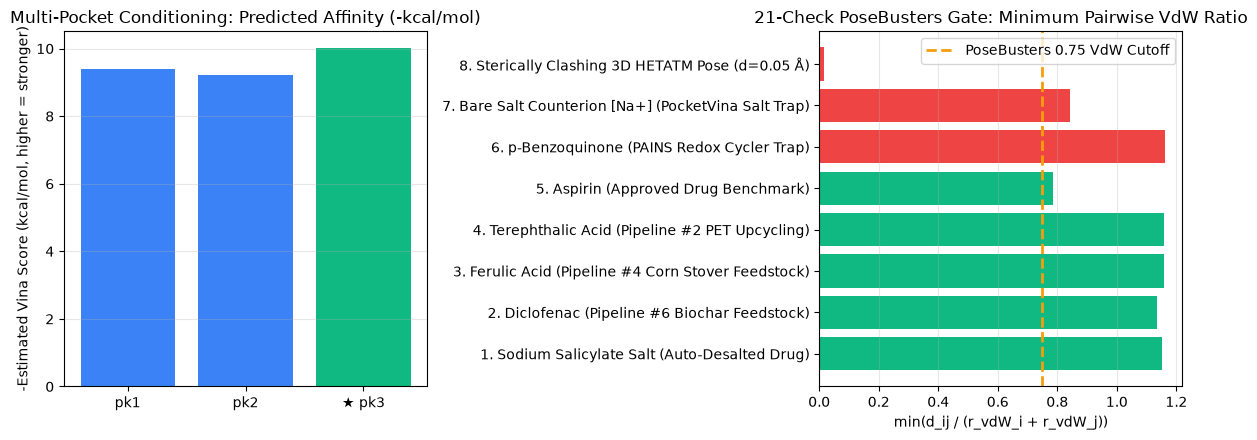

In [5]:
# Plot Multi-Pocket Conditioning Affinity & PoseBusters Score Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.bar(df_screen["pocket_badge"], -df_screen["estimated_vina_kcal_mol"], color=["#10b981" if b.startswith("★") else "#3b82f6" for b in df_screen["pocket_badge"]])
ax1.set_title("Multi-Pocket Conditioning: Predicted Affinity (-kcal/mol)")
ax1.set_ylabel("-Estimated Vina Score (kcal/mol, higher = stronger)")
ax1.grid(axis="y", alpha=0.3)

colors = ["#10b981" if "VALID" in g else "#ef4444" for g in df_audit["PoseBusters Gate"]]
ax2.barh(df_audit["Archetype"], df_audit["Min VdW Ratio (>=0.75)"], color=colors)
ax2.axvline(0.75, color="#f59e0b", linestyle="--", linewidth=2, label="PoseBusters 0.75 VdW Cutoff")
ax2.set_title("21-Check PoseBusters Gate: Minimum Pairwise VdW Ratio")
ax2.set_xlabel("min(d_ij / (r_vdW_i + r_vdW_j))")
ax2.legend()
ax2.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()